In [ ]:
!pip install duckdb geopandas shapely pyogrio pyarrow h3

#Stage 1

In [ ]:
import os
import urllib.request
import zipfile
import glob
import duckdb
import geopandas as gpd
import pandas as pd

# 1. Setup paths and endpoints
DATA_DIR = "data/raw"
os.makedirs(DATA_DIR, exist_ok=True)

PARQUET_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
LOOKUP_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
ZONES_ZIP_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"

def download_file(url, target_path):
    if not os.path.exists(target_path):
        print(f"Acquiring {os.path.basename(target_path)}...")
        urllib.request.urlretrieve(url, target_path)

lookup_path = os.path.join(DATA_DIR, "taxi_zone_lookup.csv")
zones_zip_path = os.path.join(DATA_DIR, "taxi_zones.zip")
download_file(LOOKUP_URL, lookup_path)
download_file(ZONES_ZIP_URL, zones_zip_path)

# Extract Shapefile
shapefile_dir = os.path.join(DATA_DIR, "taxi_zones")
with zipfile.ZipFile(zones_zip_path, "r") as z:
    z.extractall(shapefile_dir)

# Find .shp file inside directory
shp_files = glob.glob(os.path.join(shapefile_dir, "**", "*.shp"), recursive=True)
if not shp_files:
    raise FileNotFoundError(f"No .shp file found inside {shapefile_dir}")
shapefile_path = shp_files[0]

# 3. Process Spatial Geometry (Centroid Extraction)
print("Integrating spatial geometries...")
gdf = gpd.read_file(shapefile_path)
# Dissolve multi-part polygons by LocationID and repair invalid topologies
gdf = gdf.dissolve(by="LocationID", as_index=False)
gdf["geometry"] = gdf.geometry.make_valid()

# Calculate centroid in native projected CRS (EPSG:2263 - feet), then reproject to EPSG:4326 (lat/lon)
projected_centroids = gdf.geometry.centroid
latlon_centroids = gpd.GeoSeries(projected_centroids, crs=gdf.crs).to_crs(4326)
gdf["lat"] = latlon_centroids.y
gdf["lon"] = latlon_centroids.x

# Merge spatial coordinates with human-readable lookup attributes
lookup_df = pd.read_csv(lookup_path)
zones_master = gdf[["LocationID", "lat", "lon"]].merge(lookup_df, on="LocationID", how="left")

print("Streaming FULL remote trip telemetry with DuckDB...")
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")

# Direct query fetching core telemetry columns for the ENTIRE January dataset
ingest_query = f"""
    SELECT
        VendorID,
        tpep_pickup_datetime,
        tpep_dropoff_datetime,
        passenger_count,
        trip_distance,
        RatecodeID,
        PULocationID,
        DOLocationID,
        payment_type,
        fare_amount,
        extra,
        mta_tax,
        tip_amount,
        tolls_amount,
        improvement_surcharge,
        total_amount,
        congestion_surcharge
    FROM read_parquet('{PARQUET_URL}')
"""

# Execute the query and load the full ~2.9 million rows into Pandas
trips_df = con.execute(ingest_query).df()
print(f"Successfully loaded {len(trips_df):,} raw trip records into memory.")

# 5. Integrate Trips with Master Zone Table (Double Join)
print("Executing relational joins on pickup and drop-off keys...")

# Pickup integration
trips_integrated = trips_df.merge(
    zones_master.rename(columns={"lat": "PU_lat", "lon": "PU_lon", "Borough": "PU_borough", "Zone": "PU_zone"}),
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns=["LocationID", "service_zone"])

# Dropoff integration
trips_integrated = trips_integrated.merge(
    zones_master.rename(columns={"lat": "DO_lat", "lon": "DO_lon", "Borough": "DO_borough", "Zone": "DO_zone"}),
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).drop(columns=["LocationID", "service_zone"])

print(f"Stage 1 Complete: {len(trips_integrated):,} integrated trip records created.")

Acquiring taxi_zone_lookup.csv...
Acquiring taxi_zones.zip...
Integrating spatial geometries...
Streaming FULL remote trip telemetry with DuckDB...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Successfully loaded 2,964,624 raw trip records into memory.
Executing relational joins on pickup and drop-off keys...
Stage 1 Complete: 2,964,624 integrated trip records created.



# Stage 2: Data Quality Audit & Cleaning Waterfall
**Course:** DS-311 Data Mining | **Project:** DRIFT (NYC Mobility Pattern Miner)
, data quality must be assessed across five dimensions: **Completeness, Validity, Accuracy, Consistency, and Uniqueness**[cite: 24].
In this notebook, we take the integrated dataset (trips merged with spatial taxi zones) and apply a strict cleaning waterfall. We will document every row removed or modified to build our final Decision Log[cite: 24].

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_integrated is the output from Stage 1 (Acquire & Integrate)
# For the sake of this notebook, we load the merged dataframe
df = trips_integrated.copy()

# Initialize our tracking waterfall
total_raw_rows = len(df)
print(f"Starting Dataset Size: {total_raw_rows:,} rows")

Starting Dataset Size: 2,964,624 rows


## 1. Uniqueness (Deduplication)
 Principle:** "There should be no unintended extra or duplicate records"[cite: 24].
Because the TLC dataset aggregates telemetry from multiple hardware vendors, network timeouts can cause the same trip to be transmitted twice[cite: 5, 10]. We define a "duplicate" as a ride with the exact same pickup time, drop-off time, pickup location, drop-off location, and fare[cite: 5, 24].

In [ ]:
# Identify duplicated records based on trip signature
duplicate_count = df.duplicated(subset=['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'PULocationID', 'DOLocationID', 'fare_amount']).sum()

# Action: Drop duplicates
df = df.drop_duplicates(subset=['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'PULocationID', 'DOLocationID', 'fare_amount'])

print(f"Action: Removed {duplicate_count:,} duplicate rows.")
print(f"Remaining rows: {len(df):,}")

Action: Removed 124 duplicate rows.
Remaining rows: 2,964,500


## 2. Profiling Central Tendency & Skewness
Before imputing missing values or defining outliers, we must understand the shape of our data. If an attribute is symmetric, Mean $\approx$ Median $\approx$ Mode[cite: 22]. If it is right-skewed, Mode $<$ Median $<$ Mean, meaning extreme values inflate the mean and we should rely on the **Median** or **Mode**[cite: 22].

In [ ]:
def profile_distribution(series, name):
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode()[0]

    print(f"--- {name} ---")
    print(f"Mean   : {mean_val:.2f}")
    print(f"Median : {median_val:.2f}")
    print(f"Mode   : {mode_val:.2f}")
    if mean_val > median_val > mode_val:
        print("Shape  : Right-Skewed (Mode < Median < Mean)\n")
    else:
        print("Shape  : Symmetric / Other\n")

profile_distribution(df['fare_amount'], "Fare Amount")
profile_distribution(df['trip_distance'], "Trip Distance")

--- Fare Amount ---
Mean   : 18.18
Median : 12.80
Mode   : 8.60
Shape  : Right-Skewed (Mode < Median < Mean)

--- Trip Distance ---
Mean   : 3.65
Median : 1.68
Mode   : 0.00
Shape  : Right-Skewed (Mode < Median < Mean)



## 3. Completeness (Handling Nulls)
 Missing value treatment depends on the attribute's meaning[cite: 24].
* `passenger_count` and `RatecodeID` are discrete/categorical inputs manually entered by the driver[cite: 10, 14, 22]. When forgotten, they appear as Null. We replace them with the **Mode**[cite: 22, 24].
* `fare_amount` is our **Target Variable** ($Y$). We never impute the target variable because it introduces target leakage[cite: 5, 26]. Rows missing the target are removed[cite: 24].

In [ ]:
# 1. RESET THE DATAFRAME (Run this to undo previous fillna executions)
df = trips_integrated.copy()

print("==================================================")
print("PHASE 1: FINDING THE MISSING DATA")
print("==================================================")

# 2. Check for standard structural Nulls (NaN)
print("--- Standard Nulls (NaN) ---")
print(df[['passenger_count', 'RatecodeID', 'fare_amount']].isna().sum())

# 3. Check for Hidden Nulls (Driver Omissions recorded as 0)
# A taxi ride with 0 passengers is physically impossible; it is a missing value.
hidden_zero_passengers = (df['passenger_count'] == 0).sum()
print("\n--- Hidden Nulls (0 values) ---")
print(f"passenger_count containing 0: {hidden_zero_passengers:,}")

# 4. Find the Mode (most frequent value)
mode_passenger = df['passenger_count'].mode()[0]
mode_ratecode = df['RatecodeID'].mode()[0]

# 5. Convert hidden 0s to NaN so fillna() can process them all at once
df['passenger_count'] = df['passenger_count'].replace(0, np.nan)

# 6. Impute Discrete Attributes with Mode
df['passenger_count'] = df['passenger_count'].fillna(mode_passenger)
df['RatecodeID'] = df['RatecodeID'].fillna(mode_ratecode)

# 7. Drop rows missing the target variable (fare_amount)
initial_len = len(df)
df = df.dropna(subset=['fare_amount'])
dropped_targets = initial_len - len(df)

print(f"Action: Replaced NaNs & 0s in passenger_count with Mode ({mode_passenger})")
print(f"Action: Replaced NaNs in RatecodeID with Mode ({mode_ratecode})")
print(f"Action: Dropped {dropped_targets} rows missing the target fare_amount.")

# Verify the fix
print("\nVerification (Nulls & Zeros after treatment):")
print(f"NaNs left: {df['passenger_count'].isna().sum()}")
print(f"Zeros left: {(df['passenger_count'] == 0).sum()}")

PHASE 1: FINDING THE MISSING DATA
--- Standard Nulls (NaN) ---
passenger_count    140162
RatecodeID         140162
fare_amount             0
dtype: int64

--- Hidden Nulls (0 values) ---
passenger_count containing 0: 31,465
Action: Replaced NaNs & 0s in passenger_count with Mode (1)
Action: Replaced NaNs in RatecodeID with Mode (1)
Action: Dropped 0 rows missing the target fare_amount.

Verification (Nulls & Zeros after treatment):
NaNs left: 0
Zeros left: 0


## 4. Validity & Consistency (Domain Rule Enforcement)
 Values must follow agreed structural rules[cite: 24]. A fare of $-\$10$ or a trip distance of $300,000$ miles might be numerically formatted correctly, but they violate physical and economic domain constraints[cite: 5, 17, 24].
* **Consistency:** Keep LocationIDs strictly between $1$ and $263$ (264 and 265 are unmapped "Unknown" zones that break our GIS maps)[cite: 5, 15, 17].
* **Validity:** Keep dates strictly within `2024-01-01` and `2024-01-31`[cite: 5, 17].
* **Validity:** Fares must be $\ge \$2.50$ (legal TLC minimum)[cite: 5, 17].

In [ ]:
len_before = len(df)

# 1. Consistency: Spatial Mapping
df = df[(df['PULocationID'].between(1, 263)) & (df['DOLocationID'].between(1, 263))]

# 2. Validity: Temporal Bounds
df = df[(df['tpep_pickup_datetime'] >= '2024-01-01') & (df['tpep_pickup_datetime'] < '2024-02-01')]

# 3. Validity: Economic and Physical Bounds
df = df[(df['fare_amount'] >= 2.50) & (df['fare_amount'] <= 500.0)]
df = df[(df['trip_distance'] >= 0.1) & (df['trip_distance'] <= 100.0)]
df = df[(df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)]

dropped_validity = len_before - len(df)
print(f"Action: Removed {dropped_validity:,} rows violating domain validity and consistency constraints.")

Action: Removed 131,252 rows violating domain validity and consistency constraints.


## 5. Accuracy (Speed Plausibility)
 "A value can pass a range check and still be inaccurate"[cite: 24]. If a 10-mile trip is recorded as taking 30 seconds, both numbers might be legally valid, but the resulting speed ($1,200\text{ mph}$) is physically impossible[cite: 5, 17]. We calculate average speed and drop violations[cite: 5, 17].

In [ ]:
len_before = len(df)

# Calculate duration in minutes
df['duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0

# Filter impossible durations (must be between 1 minute and 3 hours)
df = df[(df['duration_min'] >= 1.0) & (df['duration_min'] <= 180.0)]

# Calculate speed in MPH and filter physical impossibilities
df['avg_speed_mph'] = df['trip_distance'] / (df['duration_min'] / 60.0)
df = df[(df['avg_speed_mph'] >= 0.5) & (df['avg_speed_mph'] <= 90.0)]

dropped_accuracy = len_before - len(df)
print(f"Action: Removed {dropped_accuracy:,} rows violating physical speed and duration accuracy.")

Action: Removed 5,346 rows violating physical speed and duration accuracy.


## 6. Outlier Investigation (The IQR Boxplot Method)
 "The IQR rule identifies a value to investigate; it does not prescribe deletion"[cite: 24].
We compute the $1.5 \times \text{IQR}$ fences to flag high fares[cite: 23]. Instead of blindly deleting them, we investigate: do these outliers represent data errors, or are they genuine airport trips with flat rates? If genuine, we **keep** them[cite: 5, 24].

--- Fare Amount IQR Fences ---
Q1: $8.60 | Q3: $19.80 | IQR: $11.20
Upper Fence: $36.60

Flagged Outliers: 288,678 trips.
Investigation: 222,417 of these outliers involve Airport flat-fares.
Decision: Retaining genuine high-value outliers as they reflect real urban pricing structures.


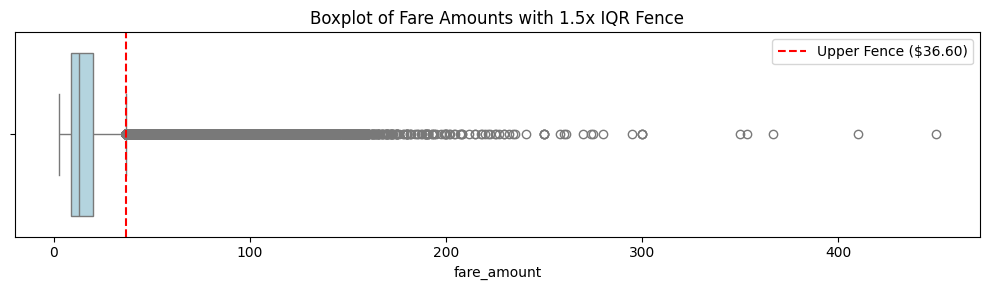

In [ ]:
# 1. Calculate 5-Number Summary and Fences
q1 = df['fare_amount'].quantile(0.25)
q3 = df['fare_amount'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print(f"--- Fare Amount IQR Fences ---")
print(f"Q1: ${q1:.2f} | Q3: ${q3:.2f} | IQR: ${iqr:.2f}")
print(f"Upper Fence: ${upper_fence:.2f}")

# 2. Investigate the Outliers
outliers = df[df['fare_amount'] > upper_fence]
print(f"\nFlagged Outliers: {len(outliers):,} trips.")

# Check how many of these outliers are actually airport trips (JFK=132, Newark=1, LaGuardia=138)
airport_outliers = outliers[outliers['PULocationID'].isin([1, 132, 138]) | outliers['DOLocationID'].isin([1, 132, 138])]
print(f"Investigation: {len(airport_outliers):,} of these outliers involve Airport flat-fares.")
print("Decision: Retaining genuine high-value outliers as they reflect real urban pricing structures.")

# 3. Generate Boxplot
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['fare_amount'], color="lightblue")
plt.axvline(upper_fence, color='red', linestyle='--', label=f'Upper Fence (${upper_fence:.2f})')
plt.title("Boxplot of Fare Amounts with 1.5x IQR Fence")
plt.legend()
plt.tight_layout()
plt.show()

## 7. The Final Cleaning Waterfall
 Summarize the total loss of information to ensure we did not introduce bias[cite: 24]. This final check verifies our data retention rate before handing the data over to the ML tracks (Modules A-D)[cite: 8].

In [ ]:
final_rows = len(df)
retention_rate = (final_rows / total_raw_rows) * 100

print("="*50)
print("STAGE 2: DATA QUALITY WATERFALL SUMMARY")
print("="*50)
print(f"Initial Raw Integrated Rows : {total_raw_rows:,}")
print(f"Duplicates Removed          : {duplicate_count:,}")
print(f"Missing Targets Removed     : {dropped_targets:,}")
print(f"Validity Rule Violations    : {dropped_validity:,}")
print(f"Accuracy Rule Violations    : {dropped_accuracy:,}")
print("-"*50)
print(f"Final Cleaned Rows          : {final_rows:,}")
print(f"Total Retention Rate        : {retention_rate:.2f}%")
print("="*50)
print("Stage 2 Complete. Dataset is ready for Feature Engineering and EDA.")

STAGE 2: DATA QUALITY WATERFALL SUMMARY
Initial Raw Integrated Rows : 2,964,624
Duplicates Removed          : 124
Missing Targets Removed     : 0
Validity Rule Violations    : 131,252
Accuracy Rule Violations    : 5,346
--------------------------------------------------
Final Cleaned Rows          : 2,828,026
Total Retention Rate        : 95.39%
Stage 2 Complete. Dataset is ready for Feature Engineering and EDA.
